<a href="https://colab.research.google.com/github/diegoo7am/Curso-Intro-Python/blob/main/Modulo_02_Aplicaciones_Financieras/2_2_pandas_descarga_activos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[⬅ Volver al índice](https://colab.research.google.com/github/diegoo7am/Curso-Intro-Python/blob/main/indice.ipynb)

# Descarga y descripción de activos financieros

### CONCEPTOS TEÓRICOS

En este curso, partiremos de la premisa de que los **precios de una acción se comportan como una variable aleatoria, cuya función de distribución es lognormal**. Esta elección se justifica porque los precios no pueden ser negativos, y su comportamiento suele presentar una asimetría positiva. Además, dado que los precios de las acciones a menudo experimentan grandes fluctuaciones en el tiempo, el uso de una distribución lognormal permite capturar este comportamiento de manera más precisa. En consecuencia, asumiremos que el logaritmo de los precios sigue una distribución normal, lo cual será clave para los análisis posteriores.


Sin embargo, en lugar de trabajar directamente con precios, nos centraremos en los rendimientos. **Los rendimientos continuos de una acción, definidos como $ r_t = \ln \left( \frac{P_t}{P_{t-1}} \right) $, se aproximan a una distribución normal**. Esto nos proporciona una manera más conveniente de modelar y analizar el comportamiento de los activos financieros. **La distribución normal está caracterizada por dos parámetros fundamentales: la esperanza o media, que representa el rendimiento esperado o más probable de la acción, y la desviación estándar, que mide la dispersión de los rendimientos en torno a esa media, sirviendo como una primera aproximación al concepto de riesgo**. Cuanto mayor sea la desviación estándar, mayor será el riesgo asociado al activo.

Este enfoque nos permitirá, a lo largo del curso, modelar y simular diferentes escenarios en los que los rendimientos de una acción puedan variar en función de estos parámetros, ayudándonos a comprender mejor el equilibrio entre rentabilidad y riesgo en los mercados financieros.

### IMPLEMENTACIÓN EN PYTHON

Pandas es una librería muy popular entre los desarrolladores de Python, y sobre todo dentro del ámbito de Data Science y Machine Learning, ya que ofrece unas estructuras muy poderosas y flexibles que facilitan la manipulación y tratamiento de datos.

* Puedes encontrar la documentación de pandas [aquí](https://pandas.pydata.org/docs/index.html)
* En particular puedes ver unos tutoriales interesantes [aquí](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)

## 1. Lectura de datos

### Desde Excel y CSV

Supongamos que tenemos datos que provienen de dos **fuentes de datos distintas**, una en formato **Excel** y otra en formato **CSV**. Queremos leer ambos ficheros y unirlos con el objetivo de tener un único conjunto de datos.

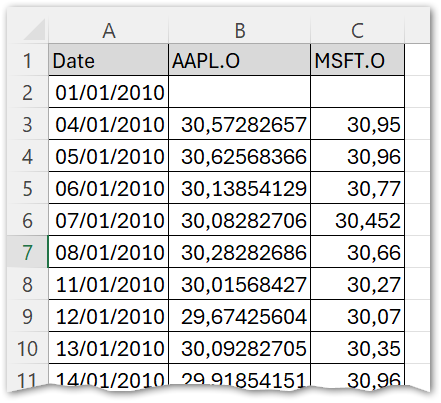

En Google Colab pandas ya viene instalado: solo hay que importarlo con el alias `pd`.

Los ficheros de datos del curso se leen directamente desde GitHub.

In [ ]:
import os
import pandas as pd

# Dirección de la carpeta con los ficheros de datos del curso
RUTA_DATOS = "https://raw.githubusercontent.com/diegoo7am/Curso-Intro-Python/main/Modulo_02_Aplicaciones_Financieras/data/"

In [ ]:
data1 = pd.read_excel(RUTA_DATOS + "data_02_parte_1.xlsx")
data1

Las estructuras que se utilizan en Pandas son:
* **DataFrame**: matriz bidimensional formado por series concatenadas en forma de filas y columnas. Cada una de las columnas es una serie
* **Series**: vector columna o matriz unidimensional que permite almacenar todo tipo de datos con un índice.

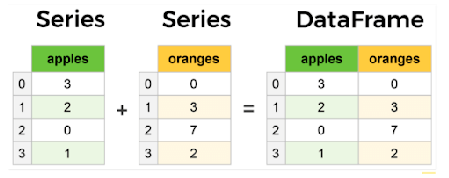

En nuestro caso, la información se ha guardado en el dataframe llamado `data1`. Mientras que `Date`, `AAPL.O` y `MSFT.O` son series.

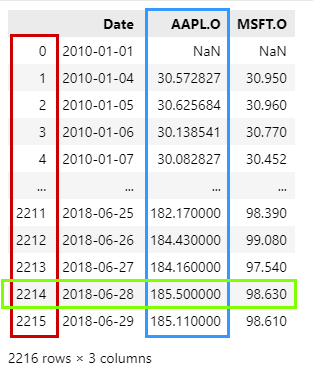

Vamos a guardar el **dataframe** como un archivo de Excel nuevo.

- `index=False` evita que Pandas añada al Excel una columna extra con los índices `0, 1, 2, ....`

In [ ]:
data1.to_excel("data1.xlsx", index=False)

In [ ]:
# Descarga el fichero a tu ordenador
from google.colab import files
files.download("data1.xlsx")

Vamos a recuperar el archivo que acabamos de guardar. Está en la carpeta `/content` de Colab: puedes verla en el icono de carpeta del panel izquierdo, y también subir desde ahí tus propios ficheros.

In [ ]:
data1 = pd.read_excel("data1.xlsx")
data1

In [ ]:
# Carpeta de trabajo actual
os.getcwd()

In [ ]:
# Ficheros que hay en la carpeta de trabajo
os.listdir()

También podemos conectar nuestro Google Drive para leer ficheros guardados en él (Colab te pedirá permiso):

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
# Ejemplo: pd.read_excel("/content/drive/MyDrive/data1.xlsx")

Una vez cargado, lo primero es ver la información general del dataframe:

In [ ]:
# Tamaño del DataFrame (filas, columnas)
data1.shape

In [ ]:
data1.info()

Ahora vamos a ser un poco más específicos a la hora de indicar a Pandas cómo debe leer el fichero Excel. Indicaremos desde qué hoja queremos leer los datos y qué columna queremos que actúe como índice de los datos `index_col="Date"`.

In [ ]:
data1 = pd.read_excel(RUTA_DATOS + "data_02_parte_1.xlsx", sheet_name="Datos", index_col="Date")
data1

In [ ]:
data1.info()

Podemos saber de qué tipo es un objeto usando el método `type`.

In [ ]:
type(data1)

Podemos saber cuál es el índice de DataFrame consultando su propiedad `index`.

In [ ]:
data1.index

#### Formato CSV

**EJERCICIO** Lee el fichero `data_02_parte_2.csv` y guárdalo en una variable llamada `data2`

In [ ]:
# Escribe aquí tu código

Ahora tenemos los datos en dos dataframes separados `data1` y `data2`. Para poder unirlos en un único dataframe, usamos **pd.concat()**.

Vamos a ver cómo funciona con unos ejemplos:

#### EJEMPLO 1:

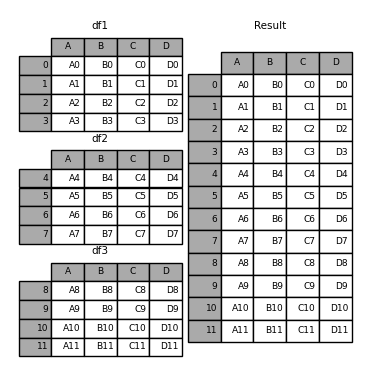

**¿Qué hace `pd.concat([])`?**
- **Columnas iguales, filas diferentes:** `pd.concat()` une DataFrames con las mismas columnas pero distintas filas.
- **Resultado:** Devuelve un DataFrame que contiene todas las filas y columnas de los DataFrames originales.

**EJERCICIO** Tienes dos DataFrames que contienen precios de cierre ajustados de las acciones de Apple (AAPL) y Microsoft (MSFT) en distintos periodos de tiempo. Los índices de ambos DataFrames son de tipo DatetimeIndex, y las fechas no se solapan: el primer DataFrame contiene datos de un rango de fechas hasta una cierta fecha, y el segundo empieza justo después de donde terminó el primero.

Se te pide concatenar estos DataFrames para formar un único DataFrame que contenga los precios de ambos periodos de tiempo.

In [ ]:
# Creación del primer DataFrame con datos hasta el 2023-01-05
dates1 = pd.date_range(start="2023-01-01", end="2023-01-05", freq="D") # Rango de fechas diarias para el índice
dicc1 = {
    'AAPL': [150.75, 152.30, 153.40, 154.60, 155.10],
    'MSFT': [250.30, 252.40, 253.10, 254.80, 255.55]
}
df1 = pd.DataFrame(dicc1, index=dates1)

# Creación del segundo DataFrame con datos a partir del 2023-01-06
dates2 = pd.date_range(start="2023-01-06", end="2023-01-10", freq="D")
dicc2 = {
    'AAPL': [156.20, 157.30, 158.10, 159.00, 160.10],
    'MSFT': [256.50, 257.60, 258.10, 259.40, 260.50]
}
df2 = pd.DataFrame(dicc2, index=dates2)

In [ ]:
# Escribe aquí tu código

In [ ]:
# Muestra los DataFrames y el resultado final

#### EJEMPLO 2:

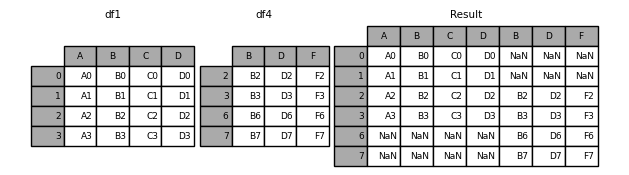

**¿Qué hace `pd.concat()` cuando los DataFrames tienen columnas y filas comunes y no comunes?**
- **Columnas y filas comunes y no comunes:** Los DataFrames que se combinan pueden tener algunas columnas y filas en común, y otras que no coinciden.
- **Resultado:** `pd.concat()` crea un nuevo DataFrame que incluye todas las columnas y filas de ambos DataFrames. Cuando una columna o fila coincide entre los DataFrames, se combinan los datos disponibles. Si alguna columna o fila no tiene datos en uno de los DataFrames, se rellena con `NaN` en esas posiciones.

In [ ]:
# Crear DataFrame 1 con precios de dos activos (AAPL y MSFT)
dicc1 = {
    'Fecha': ['2024-09-10', '2024-09-11', '2024-09-12'],
    'AAPL': [150, 152, 153],
    'MSFT': [300, 305, 310]
}
df1 = pd.DataFrame(dicc1)
df1 = df1.set_index('Fecha')


# Crear DataFrame 2 con precios de dos activos (MSFT y CSCO)
dicc2 = {
    'Fecha': ['2024-09-11', '2024-09-12', '2024-09-13'],
    'MSFT': [306, 311, 315],
    'CSCO': [50, 51, 52]
}
df2 = pd.DataFrame(dicc2)
df2 = df2.set_index('Fecha')

**EJERCICIO** concatena ambos dataframes

df1

↓

df2 debajo

axis=0 → filas

axis=1 → columnas

In [ ]:
# Escribe aquí tu código

In [ ]:
# Prueba ahora a concatenarlos con axis=1

Prueba lo que pasa si añades el ignore_index=True del comando

In [ ]:
# Escribe aquí tu código

#### EJEMPLO 3:

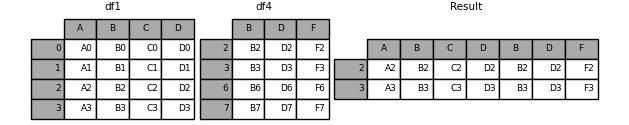

**¿Qué hace `pd.concat()` con `join="inner"` y `axis=1`?**
- **Filas comunes:** Solo se mantienen las filas que existen en ambos DataFrames.
- **Resultado:** El DataFrame final incluye solo las columnas y filas donde hay datos en ambos DataFrames.

In [ ]:
# Junta df1 y df2 con axis=1 y join="inner"

Prueba los que pasa si eliminas axis=1 del comando

In [ ]:
# Escribe aquí tu código

**EJERCICIO** Concatena data1 y data2

In [ ]:
# Escribe aquí tu código

Si ahora especificamos no solo qué columna queremos como índice, sino también que Pandas convierta automáticamente las cadenas que parezcan una fecha en un tipo fecha...

In [ ]:
data2 = pd.read_csv(RUTA_DATOS + "data_02_parte_2.csv", index_col="Date", parse_dates=True)
data2

In [ ]:
data2.index

In [ ]:
data = pd.concat([data1, data2], axis=1)
data

# 2. Slicing

**EJERCICIO** Selecciona los datos de "AAPL.O" en una serie que denominaremos `a`

In [ ]:
# Escribe aquí tu código

In [ ]:
type(a)

In [ ]:
data[["AAPL.O"]]  # Con doble corchete obtenemos un DataFrame

In [ ]:
type(data[["AAPL.O"]])

**EJERCICIO** Seleccionamos la serie de datos que tiene por nombre de columna "AAPL.O" y luego seleccionamos el valor que tiene en la fecha "2010-01-06".

In [ ]:
# Escribe aquí tu código

Para extraer información de un ``DataFrame`` usaremos muy habitualmente las funciones ``loc`` e ``iloc``:

- ``loc``: nos permite hacer *slicing* utilizando los valores del índice y/o las columnas.

- ``iloc``: nos permite hacer *slicing* utilizand las posiciones en el índice y/o las columnas.

In [ ]:
# Selecciona todas las filas y solo la columna "AAPL.O".
data.loc[:, "AAPL.O"]

In [ ]:
# Selecciona todas las filas y solo la columna en la posición 0.
data.iloc[:, 0]

In [ ]:
# Selecciona la fila con fecha "2018-06-25" y las columnas "AAPL.O" y "MSFT.O".
data.loc["2018-06-25", ["AAPL.O", "MSFT.O"]]

In [ ]:
# Selecciona las filas con fechas entre "2018-05" y "2018-06-10" y las columnas "AAPL.O" y "MSFT.O".
data.loc["2018-05":"2018-06-10", ["AAPL.O", "MSFT.O"]]

In [ ]:
# Selecciona las 5 primeras filas.
data.iloc[:5]

**EJERCICIO** Selecciona los 10 primeros días del 2018 usando `.loc` e `.iloc`

In [ ]:
# Escribe aquí tu código

## 3. Inspección de los datos

In [ ]:
data = pd.read_csv(RUTA_DATOS + "data_01.csv", index_col="Date", parse_dates=True)
data

Obtener información de los datos que contiene el DataFrame con ``info`` y ``describe``.
* ``info``: nos da información sobre los tipos y el rango de valores del índice y sobre el tipo y valores nulos de las columnas.
* ``describe``: nos da información estadística básica de las columnas numéricas.

In [ ]:
data.info()

In [ ]:
data.describe()

Examinar datos nulos

In [ ]:
import missingno as mso

mso.matrix(data)

In [ ]:
# Contamos el número de nulos en cada columna.
data.isnull().sum()

## EJERCICIO: Análisis inicial de Series de Precios de Activos Financieros:

1- **Descarga de Datos**:

  Descarga los archivos de precios históricos de tres activos financieros diferentes (AAPL.xlsx, MSFT.xlsx y CSCO.csv).

2- **Concatenación de datos**

  Selecciona únicamente la columna Cierre Ajustado de cada DataFrame, renombrándolas para que representen el ticker de cada activo (AAPL, MSFT, y CSCO).

    Junta todos en un único dataframe

3- **Inspección Inicial**:

  Muestra las primeras 10 filas del DataFrame resultante para revisar la estructura y contenido de los datos.

  Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.

4- **Slicing de datos**:

  Realiza un slicing para seleccionar solo las filas correspondientes al año 2024.

  Crea una nueva tabla que contenga los datos de precios de cierre de los activos seleccionados para las primeras 60 observaciones de 2024.

5- **Análisis Exploratorio Básico**:

  Calcula el número de días en los que los precios de cierre estuvieron disponibles para cada activo en 2024.

  Calcula la media de los precios de cierre para cada activo durante el año 2024, ignorando los valores nulos.

6- **Exportación de Datos**:

  Guarda el DataFrame final en un nuevo archivo CSV llamado precios_consolidados_2024.csv.

1- **Descarga de Datos**:

  Descarga los archivos de precios históricos de tres activos financieros diferentes (AAPL.xlsx, MSFT.xlsx y CSCO.csv).

In [ ]:
# 1. Cargar los datos desde la carpeta de datos y establecer la columna 'Date' como índice
df_aapl = pd.read_excel(RUTA_DATOS + "AAPL.xlsx", index_col="Date", parse_dates=True)
df_msft = pd.read_excel(RUTA_DATOS + "MSFT.xlsx", index_col="Date", parse_dates=True)
df_csco = pd.read_csv(RUTA_DATOS + "CSCO.csv", index_col="Date", parse_dates=True)

In [ ]:
df_aapl.head()

2- **Concatenación de datos**

  Selecciona únicamente la columna Cierre Ajustado de cada DataFrame, renombrándolas para que representen el ticker de cada activo (AAPL, MSFT, y CSCO).

  Junta todos en un único dataframe

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

3- **Inspección Inicial**:

  Muestra las primeras 10 filas del DataFrame resultante para revisar la estructura y contenido de los datos.

  Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

4- **Slicing de datos**:

  Realiza un slicing para seleccionar solo las filas correspondientes al año 2024.

  Crea una nueva tabla que contenga los datos de precios de cierre de los activos seleccionados para las primeras 60 observaciones de 2024.

In [ ]:
# Selecciono los datos de 2024

In [ ]:
# Selecciono los datos de 2024 y los primeros 60 días

5- **Análisis Exploratorio Básico**:

  Calcula el número de días en los que los precios de cierre estuvieron disponibles para cada activo en 2024.

  Calcula la media de los precios de cierre para cada activo durante el año 2024, ignorando los valores nulos.

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

6- **Exportación de Datos**:

  Guarda el DataFrame final en un nuevo archivo CSV llamado precios_consolidados_2024.csv.

In [ ]:
# Escribe aquí tu código

## 4. Limpieza de datos

¿Qué podemos hacer ahora?
* Eliminar las filas que no contienen datos.
* Rellenar los datos faltantes.
* Remuestrear los datos a una frecuencia menor.
* Obtener los datos desde una fuente de datos más fiable.

Eliminar las filas que no contienen datos

In [ ]:
# Veamos los datos
mso.matrix(data)

`data.dropna(how="any",axis=1)`
Borra las columnas que tenga al menos un NaN


Tengo dos opciones para `how`:

how="any" → elimina si hay al menos un NaN

how="all" → elimina solo si todos los valores son NaN

In [ ]:
# Eliminamos las columnas que tengan al menos un valor nulo.
data.dropna(how="any", axis=1)

In [ ]:
# Eliminamos las filas que tengan al menos un valor nulo.
mso.matrix(data.dropna(how="any", axis=0))

Rellenar datos faltantes.

**Cuidado con rellenar datos... depende del caso de uso en el que se está trabajando.**

In [ ]:
# Rellena los NaN de cada columna con un cero.
data.fillna(0)

In [ ]:
# Rellena los NaN de cada columna con la media de cada columna.
data.fillna(data.mean())

In [ ]:
# Rellena los NaN de cada columna con el último valor conocido hacia adelante.
data.ffill()

In [ ]:
# Rellena los NaN de cada columna con el último valor conocido hacia atrás.
data.bfill()

In [ ]:
# Rellena los NaN de cada columna con el último valor conocido primero hacia delante y luego hacia atrás.
data.ffill().bfill()

Remuestrear los datos a una frecuencia menor.

In [ ]:
# Remuestrea los datos de días a semanas usando el último valor conocido el miércoles de cada semana.
data.resample("W-WED").last()

In [ ]:
data.resample("W-MON").last()   # lunes
data.resample("W-TUE").last()   # martes
data.resample("W-WED").last()   # miércoles
data.resample("W-THU").last()   # jueves
data.resample("W-FRI").last()   # viernes
data.resample("W-SAT").last()   # sábado
data.resample("W-SUN").last()   # domingo

Otras frecuencias útiles

In [ ]:
data.resample("D").last()       # diario
data.resample("B").last()       # día hábil
data.resample("W-FRI").last()   # semanal, viernes
data.resample("ME").last()      # fin de mes
data.resample("MS").first()     # inicio de mes
data.resample("QE").last()      # fin de trimestre
data.resample("YE").last()      # fin de año

También puedes combinar resample() con distintas operaciones:

In [ ]:
# Remuestrea los datos usando el último valor conocido en la fecha de fin de mes.
data.resample("ME").last()

In [ ]:
data.resample("ME").last()      # último dato del mes
data.resample("ME").first()     # primer dato del mes
data.resample("ME").mean()      # media mensual
data.resample("ME").max()       # máximo mensual
data.resample("ME").min()       # mínimo mensual
data.resample("ME").sum()       # suma mensual

Obtener los datos desde una fuente más fiable

**La API de Yahoo Finance** permite acceder programáticamente a datos financieros, incluidos precios históricos, cotizaciones en tiempo real, datos fundamentales y noticias de mercado. En Python utilizaremos la librería `yfinance`.

Para más información de los datos que proporciona lo puedes ver en la [documentación de yfinance](https://ranaroussi.github.io/yfinance/)

In [ ]:
%pip install -q yfinance

**Importante:** en el curso trabajamos siempre con el precio de cierre ajustado (`Adj Close`), que corrige el precio por dividendos y *splits*.

- `auto_adjust=False` → `yf.download()` devuelve las columnas `Close` (sin ajustar) y `Adj Close`.
- `auto_adjust=True` (valor por defecto en las versiones actuales de `yfinance`) → la columna `Adj Close` desaparece y `Close` pasa a contener el precio ajustado.

Por eso indicaremos siempre `auto_adjust=False` y seleccionaremos la columna `Adj Close`.

In [ ]:
import yfinance as yf

data = yf.download(["AAPL", "GLD", "MSFT", "SPY"], start="2018-12-31", end="2023-12-31", auto_adjust=False)
data

In [ ]:
data = data.loc[:, "Adj Close"]
data

In [ ]:
data.info()

In [ ]:
data.describe()

## 5. Visualización

Hasta ahora hemos visto cómo descargar y limpiar los datos, pero nos falta un ejercicio importante que es el que más ayuda a analizar los datos: **visualizarlos**.

Veremos dos formas de visualizar datos:

- Usando los **métodos de visualización de Pandas** para un análisis rápido e inicial.

- Usando **Matplotlib** para crear gráficos más desarrollados y personalizados.

Para ver la documentación de cómo hacer gráficos con Pandas ver [Visualización con Pandas](https://pandas.pydata.org/docs/getting_started/intro_tutorials/04_plotting.html)

Representa gráficamente los datos contenidos en el DataFrame data.
'data.plot(...)'

Pandas utilizará normalmente:
- el índice (Fecha) como eje X;
- las columnas (AAPL, GLD, MSFT, SPY) como variables a representar.

In [ ]:
data.plot()

`figsize=(12, 4)`

Controla el tamaño de la figura: figsize=(ancho, alto), 12 pulgadas de ancho y 4 pulgadas de alto.

`subplots=True`

crea un gráfico diferente para cada columna

In [ ]:
data.plot(figsize=(12, 4), subplots=True)

**Matplotlib** es una biblioteca de Python utilizada para crear gráficos y visualizaciones de datos en 2D. Es altamente configurable y permite generar gráficos de líneas, barras, dispersión, histogramas, entre otros, con opciones para personalizar colores, estilos y etiquetas.

Puedes encontrar la documentación en [matplotlib](https://matplotlib.org/)

En nuestro caso, ¿cómo puedo graficar estas series de precios?

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
plt.figure(figsize=(10,3)) # Indico el tamaño
plt.plot(data["AAPL"], label="AAPL") # Defino las leyendas
plt.plot(data["GLD"], label="GLD")
plt.plot(data["MSFT"], label="MSFT")
plt.plot(data["SPY"], label="SPY")
plt.title("Precios de cierre ajustados") #Defino el título
plt.grid(True) # Le pongo una rejilla
plt.legend() # le indico que refleje las leyendas
plt.show()

Por defecto `plt.legend(loc="upper right")`

Otras opciones:
- "upper right"
- "upper left"
- "lower right"
- "lower left"
- "center"
- "center left"
- "center right"
- "upper center"
- "lower center"
- "best"

Además puedo poner un título a leyenda:

`plt.legend(title="Activos")`

Determinar el tamaño de letra

`plt.legend(title="Activos", fontsize=10)`

Determinar el número de columnas

`plt.legend(ncol=2)`

Quitar o mantener recuadro

`plt.legend(frameon=False)`

Poner leyenda fuera del cuadro:

`bbox_to_anchor` permite posicionarla con más precisión.

`plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)`

Cambiar el tamaño de los marcadores, pero debo definir previamente un marcador.

`plt.legend(markerscale=2)`

In [ ]:
plt.figure(figsize=(10,3)) # Indico el tamaño
plt.plot(data["AAPL"], label="AAPL",marker="o") # Defino un marcados
plt.plot(data["GLD"], label="GLD")
plt.plot(data["MSFT"], label="MSFT")
plt.plot(data["SPY"], label="SPY")
plt.title("Precios de cierre ajustados") #Defino el título
plt.grid(True) # Le pongo una rejilla
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    title="Activos",
    fontsize=10,
    ncol=2,
    frameon=False,
    markerscale=2
)
plt.show()

Tipo de marcadores:
- marker="o"   # círculo
- marker="s"   # cuadrado
- marker="^"   # triángulo arriba
- marker="v"   # triángulo abajo
- marker="<"   # triángulo izquierda
- marker=">"   # triángulo derecha
- marker="D"   # rombo
- marker="d"   # rombo pequeño
- marker="*"   # estrella
- marker="+"   # cruz
- marker="x"   # aspa
- marker="p"   # pentágono
- marker="h"   # hexágono
- marker="H"   # hexágono alternativo
- marker="."   # punto
- marker=","   # píxel
- marker="1"   # tri_down
- marker="2"   # tri_up
- marker="3"   # tri_left
- marker="4"   # tri_right

## Ejercicio de Repaso: Análisis y Visualización de Datos Financieros

### Objetivos:
1. Descargar datos financieros de Yahoo Finance.
2. Realizar la inspección, limpieza y concatenación de datos.
3. Aplicar técnicas de slicing para análisis.
4. Visualizar los datos para un análisis preliminar.

### Instrucciones:

#### 1. Descarga y Preparación de Datos:
- Utiliza la librería `yfinance` para descargar el 'Adj Close' de los siguientes activos para el periodo del 1 de enero de 2015 al 31 de agosto de 2023:
  - Tesla, Inc. (TSLA)
  - NVIDIA Corporation (NVDA)
  - Meta Platforms, Inc. (META)
- Renombra las columnas de cada DataFrame utilizando el formato `Activo_Columna` (por ejemplo, `TSLA_AdjClose`, `NVDA_AdjClose`, etc.).
- Junta todos los DataFrames en un único DataFrame llamado `df_concatenado`, utilizando la fecha como índice.
- Después de la concatenación, crea un nuevo DataFrame llamado `df_adj_close` que contenga las columnas de precios ajustados (`Adj Close`) de cada activo.

#### 2. Inspección Inicial:
- Muestra las primeras 10 filas del DataFrame `df_adj_close` para revisar su estructura y contenido.
- Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.
- Utiliza `info()` y `describe()` para obtener una visión general de los datos.

#### 3. Slicing de Datos:
- Selecciona las filas correspondientes a los meses de julio de 2018, 2019, 2020, 2021 y 2022 y crea una nueva tabla con los precios ajustados (`Adj Close`) de esos periodo para cada activo.
- Crea una tabla con las primeras 30 observaciones del año 2023.

#### 4. Visualización de Datos:
- Genera un gráfico de líneas utilizando los métodos de visualización de pandas para mostrar la evolución de los precios ajustados de los tres activos durante el periodo completo.
- Utilizando `matplotlib`, crea un gráfico personalizado para visualizar los tres activos, incluyendo título, leyenda y cuadrícula.

#### 5. Interpretación:
- Razona en cuál de los activos analizados invertiría tu dinero.

#### 1. Descarga y Preparación de Datos:
- Utiliza la librería `yfinance` para descargar el 'Adj Close' de los siguientes activos para el periodo del 1 de enero de 2015 al 31 de agosto de 2023:
  - Tesla, Inc. (TSLA)
  - NVIDIA Corporation (NVDA)
  - Meta Platforms, Inc. (META)
- Renombra las columnas de cada DataFrame utilizando el formato `Activo_Columna` (por ejemplo, `TSLA_AdjClose`, `NVDA_AdjClose`, etc.).
- Junta todos los DataFrames en un único DataFrame llamado `df_concatenado`, utilizando la fecha como índice.
- Después de la concatenación, crea un nuevo DataFrame llamado `df_adj_close` que contenga las columnas de precios ajustados (`Adj Close`) de cada activo.

#### **Utilizamos diccionarios**

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

#### **Utiliza listas**

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

#### **Sólo con la API**

In [ ]:
# Escribe aquí tu código

#### 2. Inspección Inicial:
- Muestra las primeras 10 filas del DataFrame `df_adj_close` para revisar su estructura y contenido.
- Identifica las columnas que contienen valores nulos y muestra el número total de valores nulos por columna.
- Utiliza `info()` y `describe()` para obtener una visión general de los datos.

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

#### 3. Slicing de Datos:
- Selecciona las filas correspondientes a los meses de julio de 2018, 2019, 2020, 2021 y 2022 y crea una nueva tabla con los precios ajustados de esos periodo para cada activo.
- Crea una tabla con las primeras 30 observaciones del año 2023.

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

**RECORDATORIO**

`df_primero_30 = df_2023.iloc[:30]` como solo hemos puesto un selector, Pandas interpreta que te refieres a las filas.

#### 4. Visualización de Datos:
- Genera un gráfico de líneas utilizando los métodos de visualización de pandas para mostrar la evolución de los precios ajustados de los tres activos durante el periodo completo.
- Utilizando `matplotlib`, crea un gráfico personalizado para visualizar los tres activos, incluyendo título, leyenda y cuadrícula.

In [ ]:
# Escribe aquí tu código

In [ ]:
# Escribe aquí tu código

#### 5. Interpretación:
- Razona en cuál de los activos analizados invertirías tu dinero.

In [ ]:
# Puedes apoyarte en la rentabilidad y la volatilidad anualizadas de cada activo